Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]


Using device: cpu
Epoch 1/10 | Train Loss=0.7281 | Train Acc=79.57% | Val Acc=37.80%
Epoch 2/10 | Train Loss=0.3885 | Train Acc=87.20% | Val Acc=15.85%
Epoch 3/10 | Train Loss=0.3414 | Train Acc=88.41% | Val Acc=67.07%
Epoch 4/10 | Train Loss=0.2762 | Train Acc=91.16% | Val Acc=81.71%
Epoch 5/10 | Train Loss=0.1447 | Train Acc=94.51% | Val Acc=85.37%
Epoch 6/10 | Train Loss=0.0758 | Train Acc=96.95% | Val Acc=86.59%
Epoch 7/10 | Train Loss=0.1285 | Train Acc=96.65% | Val Acc=87.80%
Epoch 8/10 | Train Loss=0.2645 | Train Acc=95.43% | Val Acc=84.15%
Epoch 9/10 | Train Loss=0.1888 | Train Acc=95.73% | Val Acc=81.71%
Epoch 10/10 | Train Loss=0.1921 | Train Acc=93.60% | Val Acc=80.49%

✅ Final Validation Accuracy: 80.49%
                 precision    recall  f1-score   support

Artificial land       1.00      0.83      0.91         6
      Bare soil       0.33      0.33      0.33         3
       Cropland       0.00      0.00      0.00         2
      Grassland       0.96      0.93      0.9

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


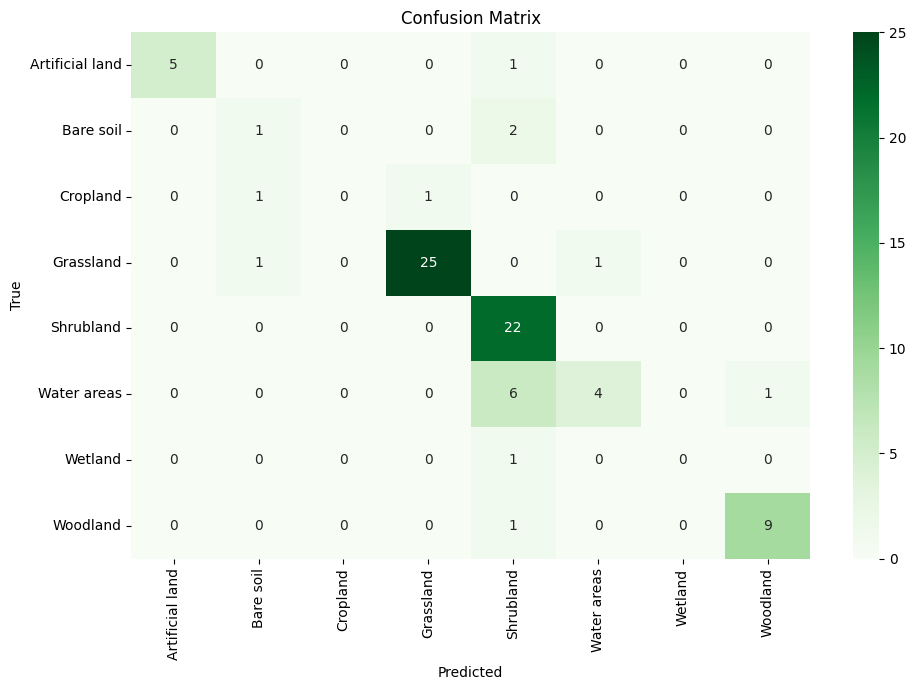

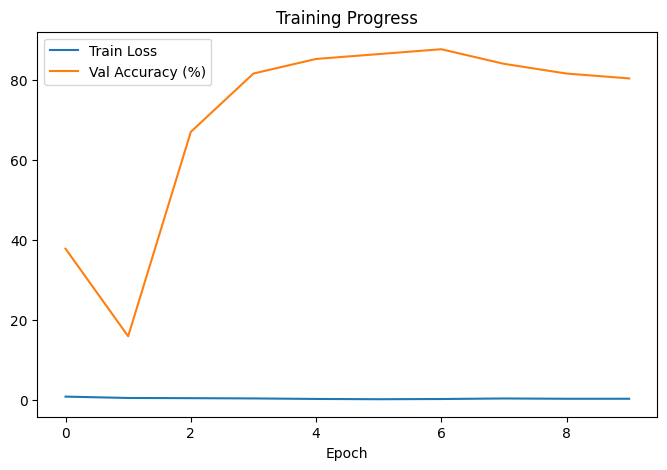

In [1]:
import os
import pandas as pd
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

IMG_DIM = 224
BATCHSZ = 32
EPOCHS = 10
DATA_CSV = '/kaggle/input/lucas-dataset/dataset_lucas_info (1).csv'
IMG_PATH = '/kaggle/input/lucas-dataset/DRLL_images'


weights = ResNet18_Weights.DEFAULT
prep = weights.transforms()

label_dict = {
    'Buildings with 1 to 3 floors': 'Artificial land',
    'Barley': 'Cropland',
    'Broadleaved woodland': 'Woodland',
    'Shrubland without tree cover': 'Shrubland',
    'Grassland without tree/shrub cover': 'Grassland',
    'Sand': 'Bare soil',
    'Inland fresh water bodies': 'Water areas',
    'Salt marshes': 'Wetland'
}

data = pd.read_csv(DATA_CSV)

data['category'] = data['lc1_label'].map(label_dict)
data = data[data['category'].notnull()].rename(
    columns={'file_path_gisco_point': 'img_name'}
).reset_index(drop=True)

df_train, df_valid = train_test_split(
    data, stratify=data['category'], test_size=0.2, random_state=1
)

class LucasImages(Dataset):
    def __init__(self, df, img_dir, transform):
        self.df = df.reset_index(drop=True)
        self.img_dir = img_dir
        self.transform = transform
        labels = sorted(self.df['category'].unique())
        self.classmap = {v: k for k, v in enumerate(labels)}
        self.inv_map = {v: k for k, v in self.classmap.items()}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        img_name = os.path.basename(self.df.loc[index, 'img_name'])
        path = os.path.join(self.img_dir, img_name)

        try:
            img = Image.open(path).convert('RGB')
        except Exception as e:
            print(f"⚠️ Failed to load {path}, using blank image. Error: {e}")
            img = Image.new('RGB', (IMG_DIM, IMG_DIM), (0, 0, 0))

        label = self.classmap[self.df.loc[index, 'category']]
        img = self.transform(img)
        return img, label

train_ds = LucasImages(df_train, IMG_PATH, prep)
valid_ds = LucasImages(df_valid, IMG_PATH, prep)
train_dl = DataLoader(train_ds, batch_size=BATCHSZ, shuffle=True)
valid_dl = DataLoader(valid_ds, batch_size=BATCHSZ)

model = resnet18(weights=weights)
model.fc = nn.Linear(model.fc.in_features, len(train_ds.classmap))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
model.to(device)

loss_fn = nn.CrossEntropyLoss()
optim_fn = optim.Adam(model.parameters(), lr=1e-3) 

train_losses, val_accs = [], []

for ep in range(EPOCHS):
    # ---- Train ----
    model.train()
    total_loss, correct, total = 0, 0, 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)

        optim_fn.zero_grad()
        pred = model(x)
        loss = loss_fn(pred, y)
        loss.backward()
        optim_fn.step()

        total_loss += loss.item()
        correct += (pred.argmax(1) == y).sum().item()
        total += y.size(0)

    train_acc = 100 * correct / total
    train_losses.append(total_loss/len(train_dl))

    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in valid_dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            _, guess = torch.max(out, 1)
            preds.extend(guess.cpu().numpy())
            trues.extend(yb.cpu().numpy())

    val_acc = 100 * np.mean(np.array(trues) == np.array(preds))
    val_accs.append(val_acc)

    print(f"Epoch {ep+1}/{EPOCHS} | Train Loss={total_loss/len(train_dl):.4f} | Train Acc={train_acc:.2f}% | Val Acc={val_acc:.2f}%")

cat_names = [valid_ds.inv_map[i] for i in range(len(valid_ds.classmap))]

print("\n✅ Final Validation Accuracy: %.2f%%" % val_accs[-1])
print(classification_report(trues, preds, target_names=cat_names))

cfm = confusion_matrix(trues, preds)
plt.figure(figsize=(10, 7))
sns.heatmap(cfm, annot=True, fmt="d", xticklabels=cat_names, yticklabels=cat_names, cmap="Greens")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_accs, label="Val Accuracy (%)")
plt.legend()
plt.title("Training Progress")
plt.xlabel("Epoch")
plt.show()
